# Random Forest - mplementation


In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
titanic = sns.load_dataset("titanic")
print(titanic.head())
titanic.isna().sum()

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [3]:
features = ["pclass", "sex", "fare", "embarked", "age"]
target = "survived"

# Handle Missing Data

imp_median = SimpleImputer(strategy="median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

In [4]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [5]:
# encode
le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

In [6]:
titanic.head(2)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False


In [7]:
X = titanic[features]
y = titanic[target]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)


In [8]:
model = DecisionTreeClassifier()

model.fit(X_train,y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training Accuracy: ", accuracy_score(y_train,y_pred_train))
print("Testing Accuracy: ", accuracy_score(y_test,y_pred_test))



Training Accuracy:  0.9791332263242376
Testing Accuracy:  0.7649253731343284


### we can see overfitting above
- Clssic case of overfitting

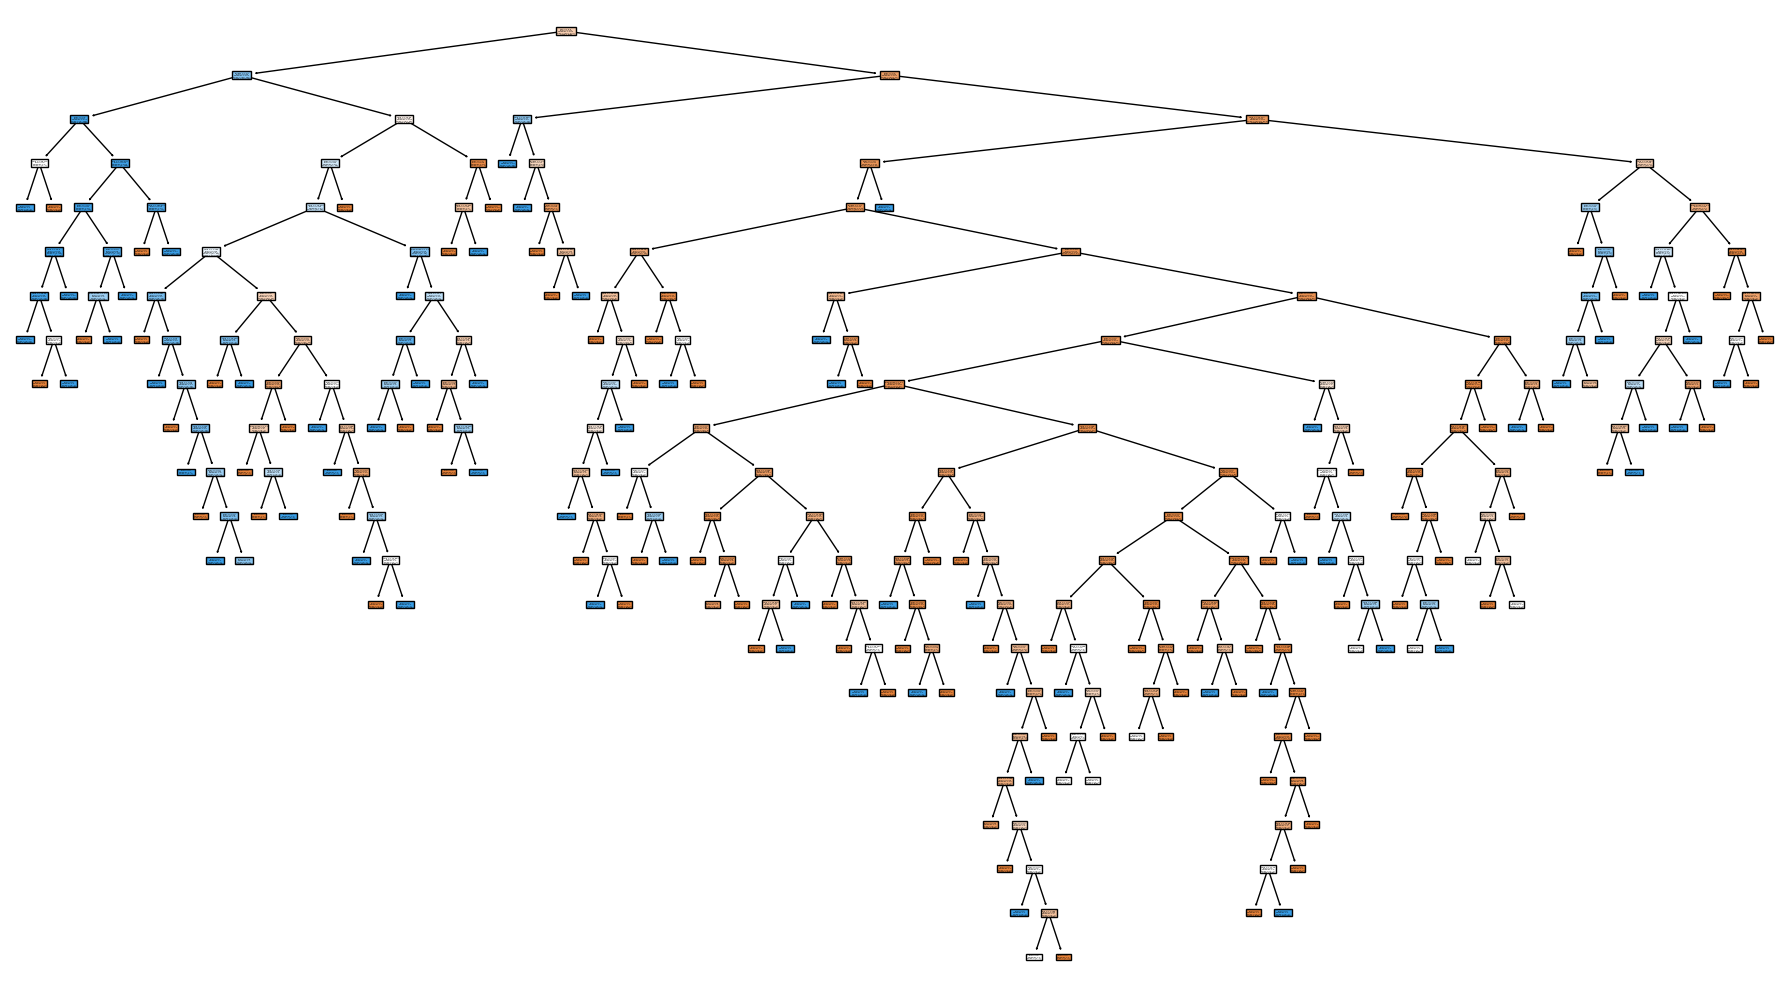

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Dies","Survived"],
    filled=True
)

plt.tight_layout()
plt.show()

#### Now Random Forest Starts

In [10]:
from sklearn.ensemble import RandomForestClassifier

# rf = RandomForestClassifier(
#     n_estimators=201, # no. of DT to create in parallel--> generally keep it odd number (default = 100)
#     #max_features="sqrt", # for column sampling (default = "sqrt")
#     oob_score=True, # out of box samples will used for validation and can find score int rf.oob_score_
#     #bootstrap=True, # if False --> whoe data set used to build each tree (default = True)
# )

rf = RandomForestClassifier(
    n_estimators=201,
    oob_score=True,
    random_state=42
)

rf.fit(X_train,y_train)

y_pred = rf.predict(X_test)

print("Out of Bag Score: ", rf.oob_score_ *100,"%") # kind of equivalent to training accuracy
print("Testing Accuracy: ", accuracy_score(y_test,y_pred) * 100,"%")



Out of Bag Score:  82.02247191011236 %
Testing Accuracy:  77.98507462686567 %


#### ABove see the difference in training and testing is less so its a good or stable model

#### we can use hyper parameter tuning here to find best parameters


## lets try pre-pruning

In [11]:
model = DecisionTreeClassifier(max_depth=4)

model.fit(X_train,y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training Accuracy: ", accuracy_score(y_train,y_pred_train))
print("Testing Accuracy: ", accuracy_score(y_test,y_pred_test))



Training Accuracy:  0.8475120385232745
Testing Accuracy:  0.8246268656716418


In [12]:
rf = RandomForestClassifier(
    n_estimators=201,
    oob_score=True,
    random_state=42,
    max_depth=4
)

rf.fit(X_train,y_train)

y_pred = rf.predict(X_test)

print("Out of Bag Score: ", rf.oob_score_ *100,"%") # kind of equivalent to training accuracy
print("Testing Accuracy: ", accuracy_score(y_test,y_pred) * 100,"%")

# Out of Bag Score:  82.34349919743178 %
# Testing Accuracy:  81.71641791044776 %
# better model

Out of Bag Score:  82.34349919743178 %
Testing Accuracy:  81.71641791044776 %
